# What reaches LoFTR? Actual input inspection

Four height-selected development frames; no locked images, training, new inference or pipeline score claim. Read `PROTOCOL_codex.md` first. The actual current baseline is 224×224; the existing optional native-fine path remains OFF. Satellite crops here use supplied truth to inspect appearance. They are not evidence that coarse search selected that tile.

Image values are displayed in fixed [0,1] with nearest-neighbour interpolation. Only the raw sensor panel has a display-only percentile stretch. The exported raw array retains its uint16 values. Satellite windows were read from the existing server store with NumPy mmap; no map was rebuilt and no server GPU job was launched.

In [1]:
from pathlib import Path
import csv
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display

root = Path.cwd().resolve()
while not (root / 'REPO_MAP.md').exists():
    root = root.parent
folder = root / 'tests/LoFTR_Inputs_20261118_codex'
results = folder / 'results'
headless = root.parent / 'Main_Pipeline_Headless'
sys.path.insert(0, str(headless))
sys.path.insert(0, str(folder / 'changed_src'))
import settings
from input_stages_codex import reconstruct_inputs, file_digest
assert settings.FLAT_FIELD_FROM_HEIGHT_M is None
assert settings.LOCAL_NORM_SIGMA is None
assert settings.PHOTO_MASK_RECTS is None
assert settings.NATIVE_FINE_FROM_HEIGHT_M is None
selected = json.loads((results / 'selected_development_codex.json').read_text())
with (root / 'tests/Test_Iteration_12/results/highalt_split.csv').open() as source:
    split = {row['filename']: row['split'] for row in csv.DictReader(source)}
image_folder = root / 'dataset/Dataset_Official_3/d1/images'
with (image_folder / 'metadata.csv').open() as source:
    metadata = {row['filename']: row for row in csv.DictReader(source)}
windows = np.load(results / 'map_windows_codex.npz')
map_provenance = json.loads(str(windows['provenance']))
print('Four development frames; default cleaning switches unchanged; heading 0, scale 1.')


Four development frames; default cleaning switches unchanged; heading 0, scale 1.


In [2]:
cases = []
measurements = []
exports = {}
for index, selection in enumerate(selected):
    filename = selection['filename']
    assert split[filename] == 'dev'
    level = selection['level']
    base_tile = windows[f'case{index}_level{level}_true']
    finer_tile = windows[f'case{index}_level{level-2}_true']
    arrays, measurement = reconstruct_inputs(image_folder / filename, metadata[filename], level, base_tile, finer_tile)
    cases.append(arrays)
    measurements.append(measurement)
    for name, value in arrays.items():
        exports[f'case{index}_{name}'] = value
np.savez_compressed(results / 'exact_input_arrays_codex.npz', **exports)
table = pd.DataFrame(measurements)
table.to_csv(results / 'sampling_measurements_codex.csv', index=False)
display(table[['height_m', 'photo_m_per_pixel', 'base_m_per_pixel', 'native_m_per_pixel', 'base_blur_sigma_photo_px', 'gradient_rms_retained_after_preblur', 'base_valid_pixels', 'source_centres_outside_canvas_percent']].round(3))
source_hashes = {}
for relative in ['settings.py', 'geoloc/photo.py', 'geoloc/fine_matching.py', 'geoloc/native_fine.py', 'geoloc/flat_field.py', 'geoloc/levels.py']:
    source_hashes[relative] = file_digest(headless / relative)
array_hashes = {}
for name, value in exports.items():
    array_hashes[name] = hashlib.sha256(value.tobytes()).hexdigest()
provenance = {'source_hashes': source_hashes, 'array_hashes': array_hashes, 'map_store': map_provenance, 'selected': selected, 'heading': 0, 'scale_factor': 1, 'default_native_fine_gate': settings.NATIVE_FINE_FROM_HEIGHT_M}
(results / 'provenance_codex.json').write_text(json.dumps(provenance, indent=2))
print('Saved original sensor arrays, intermediate stages, exact model input values, masks and hashes.')

provenance['diagnostic_block_sha256'] = file_digest(folder / 'changed_src/input_stages_codex.py')
(results / 'provenance_codex.json').write_text(json.dumps(provenance, indent=2))


Saved original sensor arrays, intermediate stages, exact model input values, masks and hashes.
Out[2]: 15083


,height_m,photo_m_per_pixel,base_m_per_pixel,native_m_per_pixel,base_blur_sigma_photo_px,gradient_rms_retained_after_preblur,base_valid_pixels,source_centres_outside_canvas_percent
0,602.9,2.979,4.800,2.400,0.556,0.689,38633,22.543
1,1002.4,4.952,9.600,4.800,0.719,0.508,32864,11.971
2,1402.2,6.928,13.576,6.788,0.730,0.398,33274,9.573
3,1886.2,9.319,13.576,6.788,0.478,0.762,44356,25.679


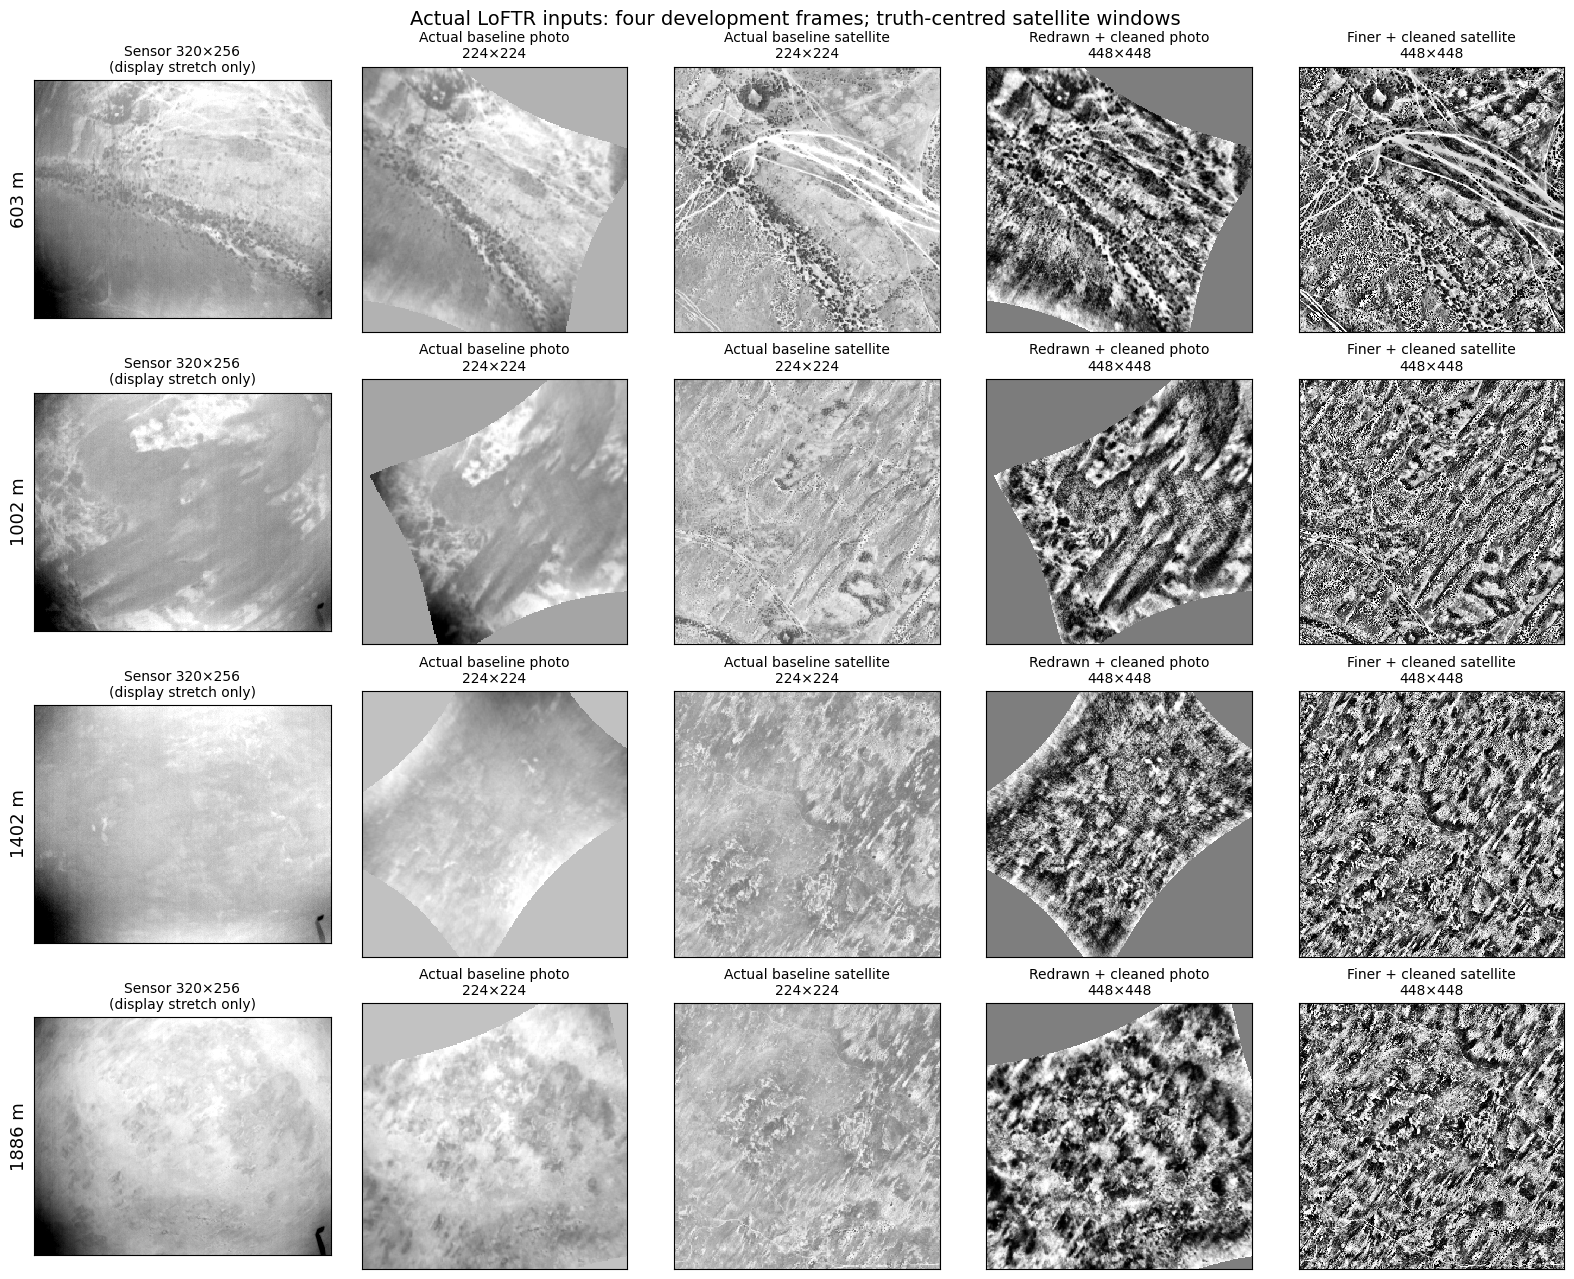

In [3]:
overview, axes = plt.subplots(4, 5, figsize=(16, 13))
columns = [('raw_display_only', 'Sensor 320×256\n(display stretch only)'), ('base_photo', 'Actual baseline photo\n224×224'), ('base_map', 'Actual baseline satellite\n224×224'), ('clean_native_photo', 'Redrawn + cleaned photo\n448×448'), ('clean_native_map', 'Finer + cleaned satellite\n448×448')]
for row, arrays in enumerate(cases):
    for col, (name, title) in enumerate(columns):
        axis = axes[row, col]
        axis.imshow(arrays[name], cmap='gray', vmin=0, vmax=1, interpolation='nearest')
        axis.set_title(title, fontsize=10)
        axis.set_xticks([])
        axis.set_yticks([])
    axes[row, 0].set_ylabel(f"{measurements[row]['height_m']:.0f} m", fontsize=13)
overview.suptitle('Actual LoFTR inputs: four development frames; truth-centred satellite windows', fontsize=14)
overview.tight_layout()
overview.savefig(results / 'input_overview_codex.png', dpi=160)
display(overview)
plt.close(overview)


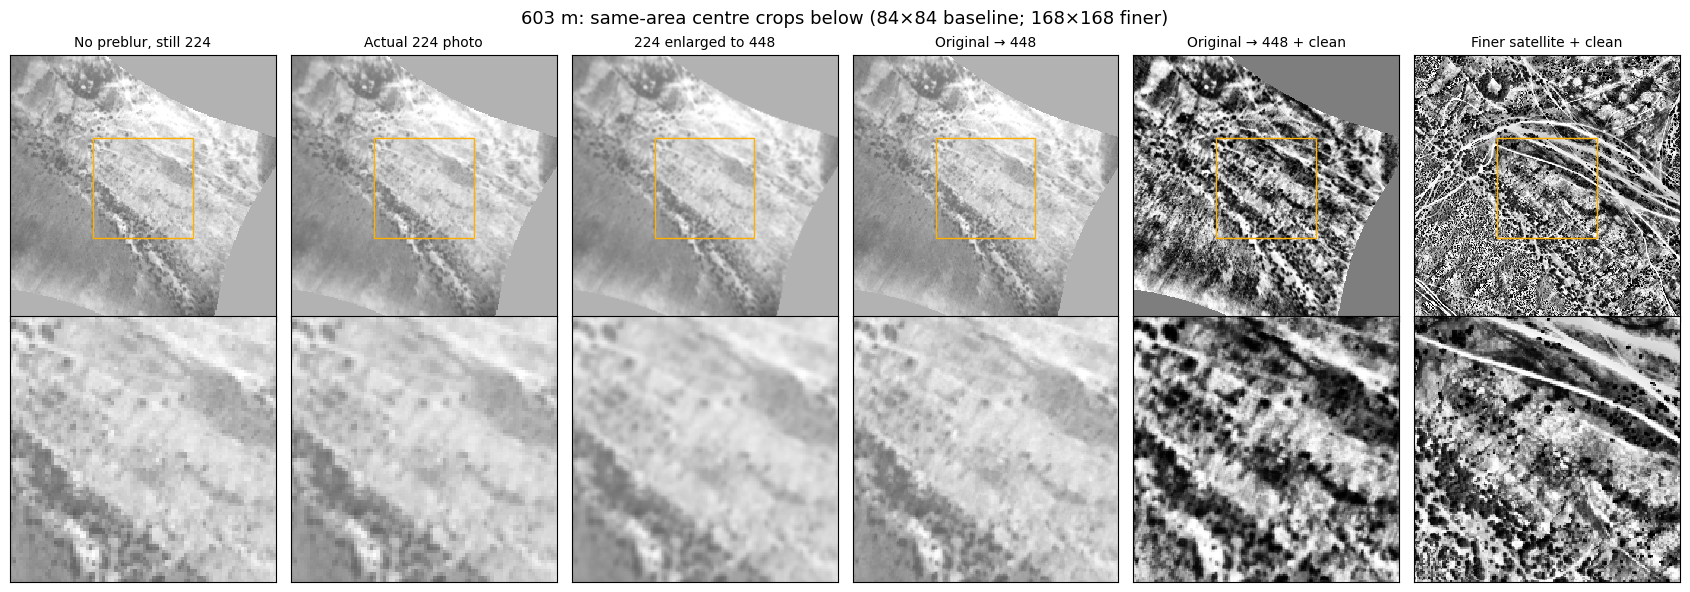

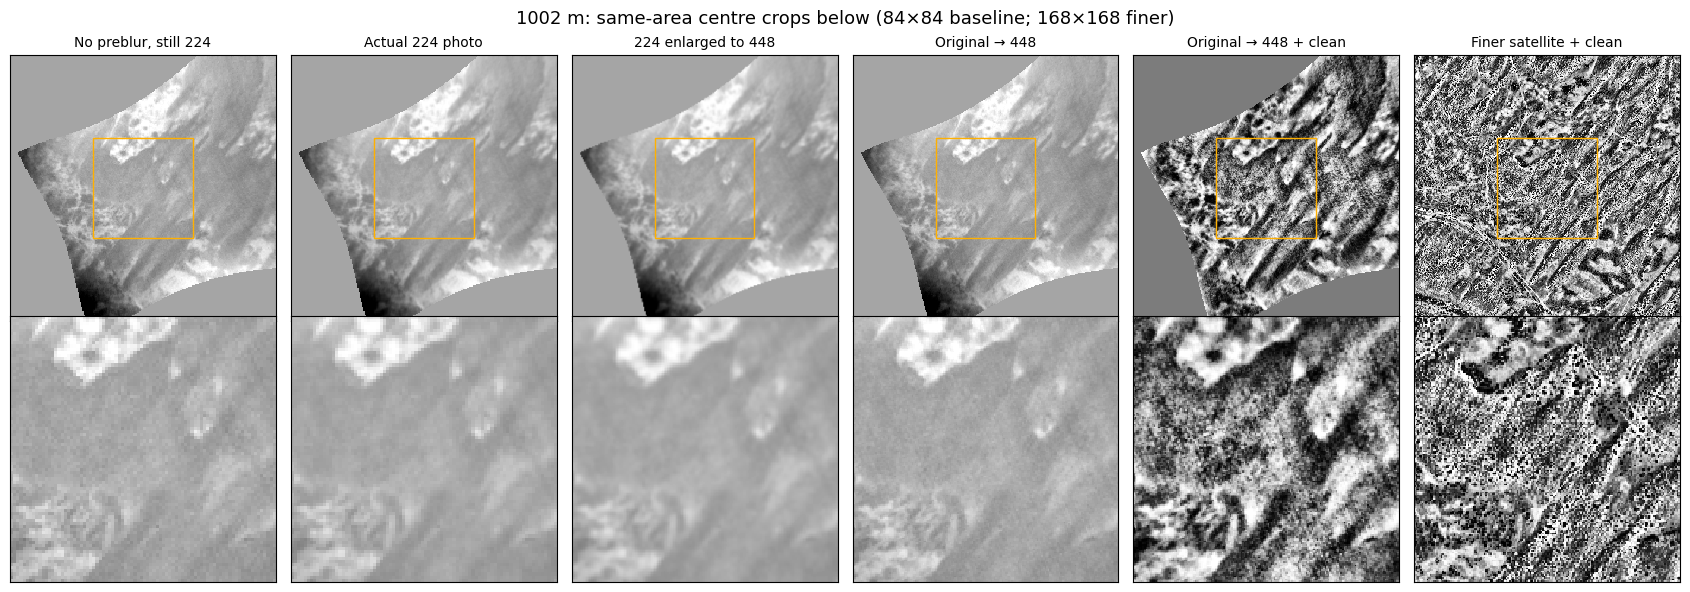

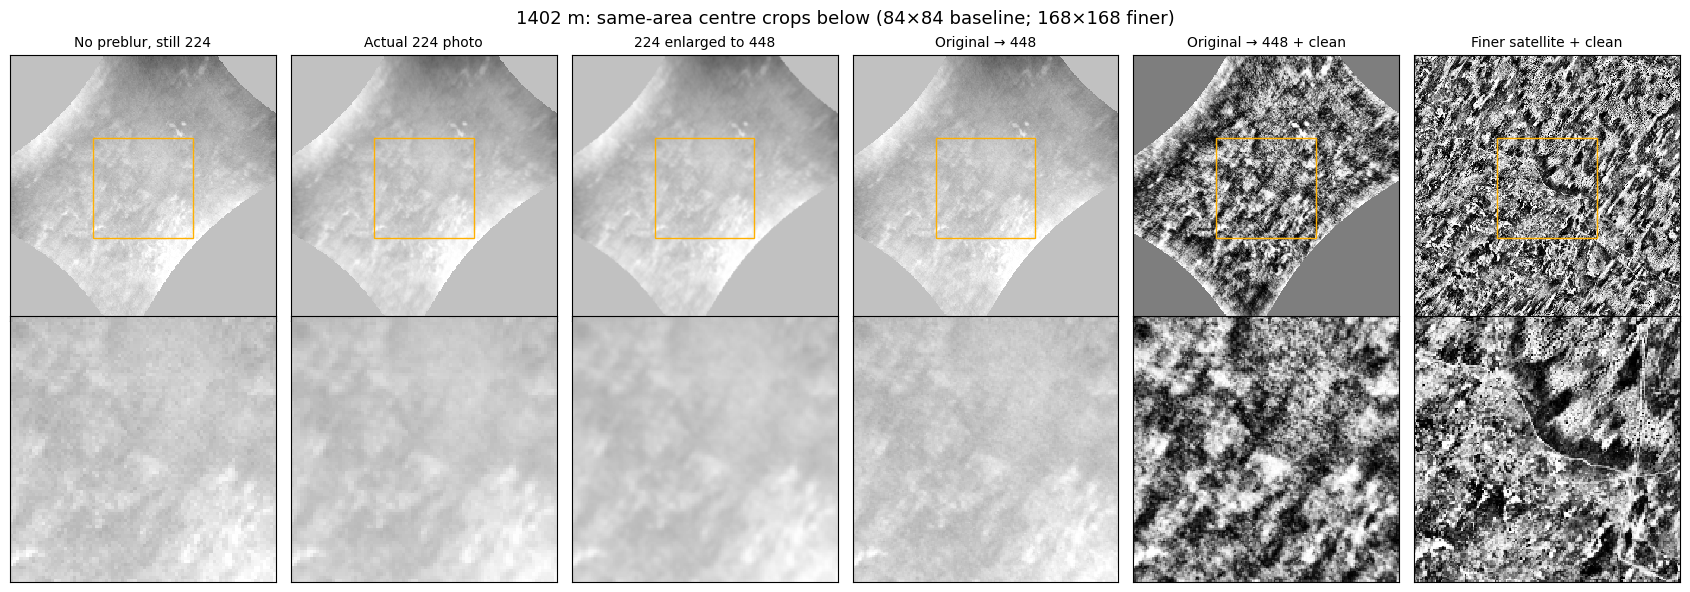

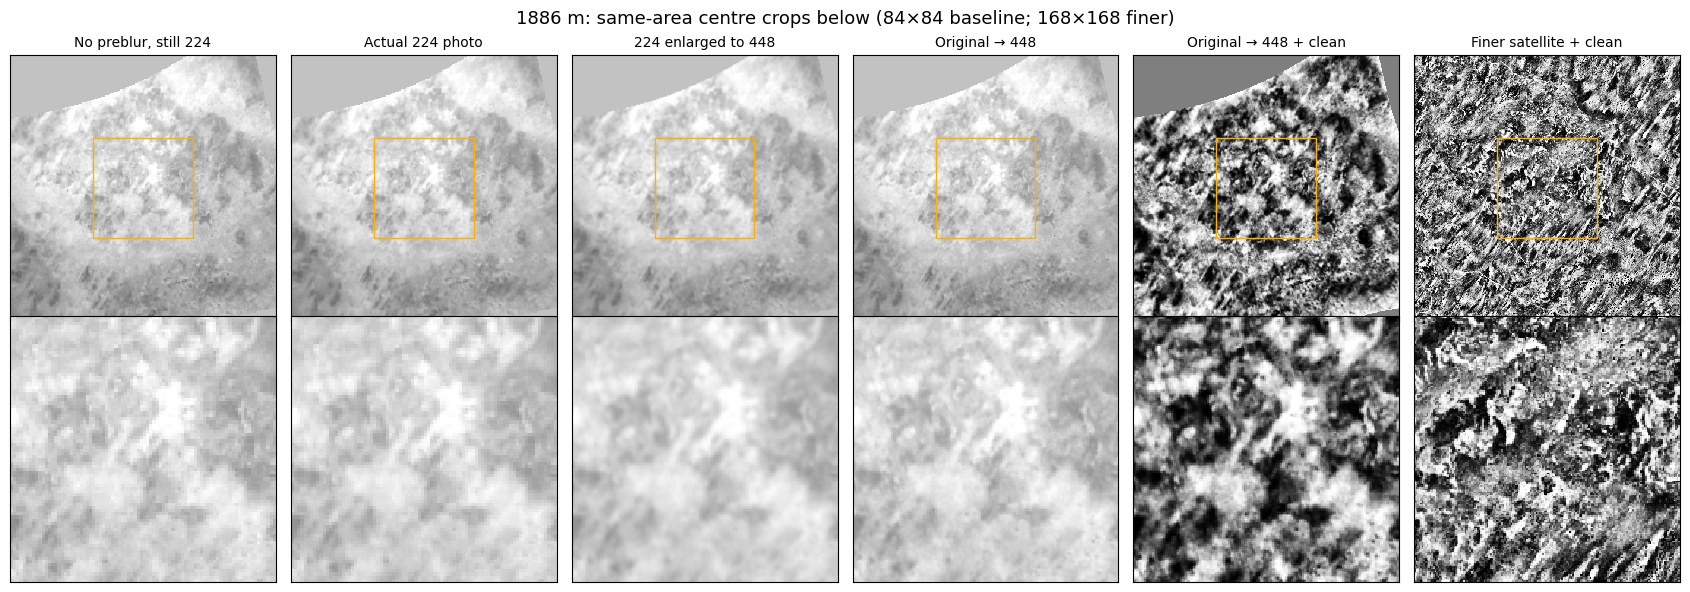

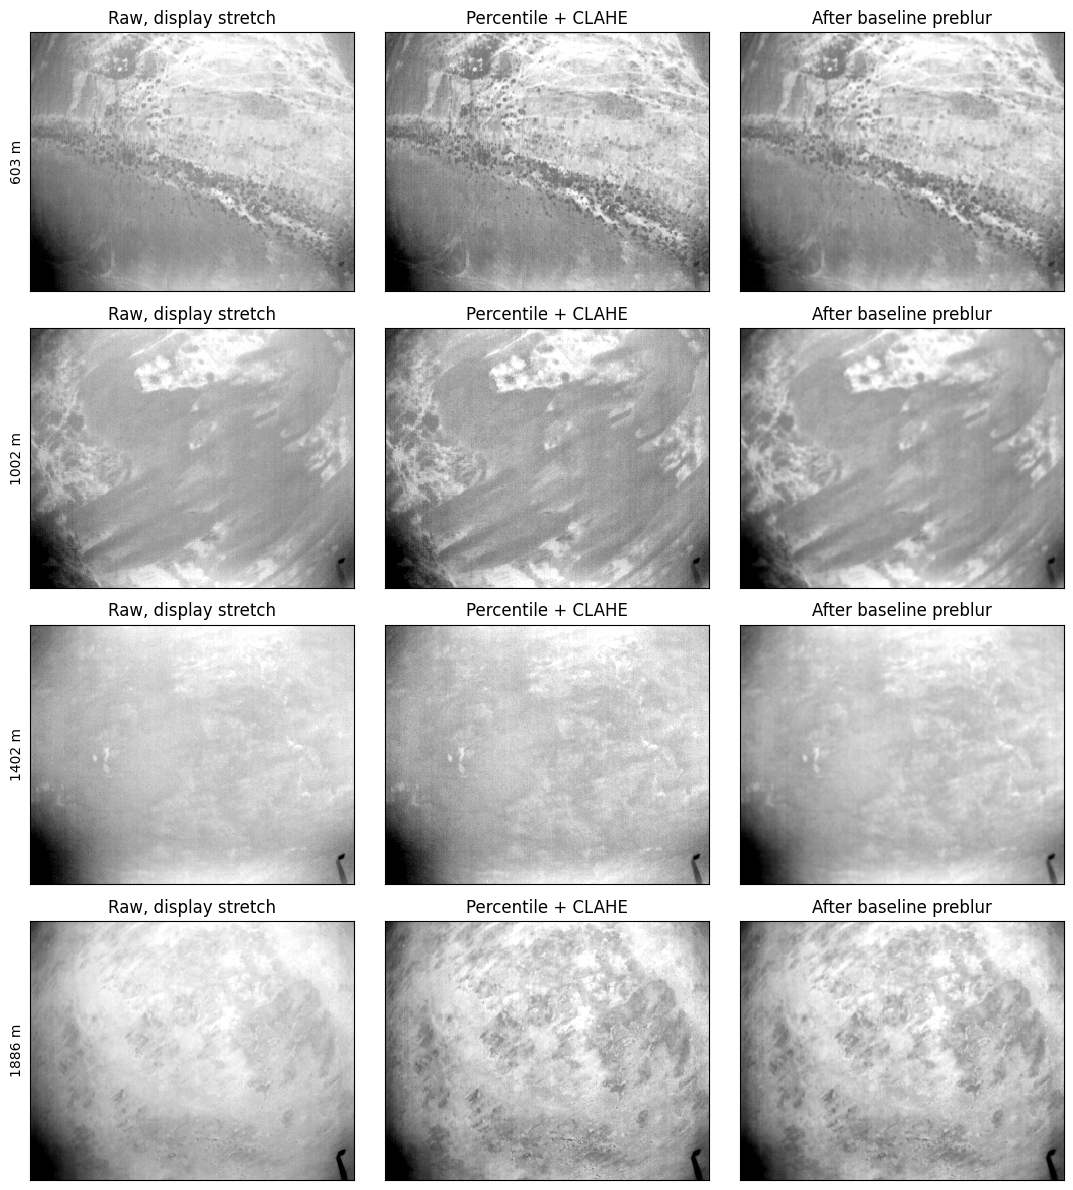

In [4]:
for index, arrays in enumerate(cases):
    figure, axes = plt.subplots(2, 6, figsize=(17, 6))
    variants = [('no_blur_photo', 'No preblur, still 224'), ('base_photo', 'Actual 224 photo'), ('upscaled_photo', '224 enlarged to 448'), ('native_photo', 'Original → 448'), ('clean_native_photo', 'Original → 448 + clean'), ('clean_native_map', 'Finer satellite + clean')]
    for col, (name, title) in enumerate(variants):
        image = arrays[name]
        size = image.shape[0]
        lower = int(size * 0.3125)
        upper = int(size * 0.6875)
        axes[0, col].imshow(image, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
        axes[0, col].add_patch(Rectangle((lower-0.5, lower-0.5), upper-lower, upper-lower, fill=False, edgecolor='#ffb000', linewidth=1))
        axes[0, col].set_title(title, fontsize=10)
        axes[1, col].imshow(image[lower:upper, lower:upper], cmap='gray', vmin=0, vmax=1, interpolation='nearest')
        for row in range(2):
            axes[row, col].set_xticks([])
            axes[row, col].set_yticks([])
    figure.suptitle(f"{measurements[index]['height_m']:.0f} m: same-area centre crops below (84×84 baseline; 168×168 finer)", fontsize=13)
    figure.tight_layout()
    figure.savefig(results / f'input_zoom_case{index}_codex.png', dpi=170)
    display(figure)
    plt.close(figure)

stages, axes = plt.subplots(4, 3, figsize=(11, 12))
for row, arrays in enumerate(cases):
    for col, (name, title) in enumerate([('raw_display_only', 'Raw, display stretch'), ('normalized_unblurred', 'Percentile + CLAHE'), ('prepared_blurred', 'After baseline preblur')]):
        axes[row, col].imshow(arrays[name], cmap='gray', vmin=0, vmax=1, interpolation='nearest')
        axes[row, col].set_title(title)
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
    axes[row, 0].set_ylabel(f"{measurements[row]['height_m']:.0f} m")
stages.tight_layout()
stages.savefig(results / 'sensor_stages_codex.png', dpi=150)
display(stages)
plt.close(stages)


Gradient RMS is a smoothing diagnostic on the same sensor grid, **not** a count of useful landmarks. Noise and camera artefacts contribute. The no-preblur control remains downsampled: sharper pixels can contain aliasing. Keep antialiasing appropriate to sampling; preserve resolution by redrawing from raw, rather than removing blur globally. The 448 label describes canvas dimensions, not a higher-resolution thermal sensor. Nominal GSD ignores local tilt and the 1.04 projection scale.

The grey outer region is mean padding passed into LoFTR without a validity mask. It contains no ground information. Native 448 retains roughly the same padding fraction. Satellite and photo centre crops cover the same nominal ground area, but residual yaw/scale/translation and sensor-modality differences remain; they are not manually registered landmark pairs.

In [5]:
previous = pd.read_csv(root / 'tests/Test_Iteration_12/results/edge_features/loftr_photo_strength.csv')
summary_rows = []
for variant, group in previous.groupby('variant', sort=False):
    summary_rows.append({'variant': variant, 'development_frames': len(group), 'true_at_least8': int((group.true_inl >= 8).sum()), 'true_at_least8_percent': 100 * (group.true_inl >= 8).mean(), 'wrong_tile_at_least8': int((group.wrong_inl >= 8).sum())})
summary = pd.DataFrame(summary_rows)
summary.to_csv(results / 'existing_iteration34_recomputed_codex.csv', index=False)
display(summary.round(2))
print('Existing Iteration 34 results, not new inference. Best of six queries at the supplied true location.')
print('A fitted 8-inlier result is not a full-pipeline acceptance: the oracle diagnostic omits the final centre-shift gate and candidate search.')
print('No new score or wrong-answer (>8 sigma) rate was measured in this inspection.')


Existing Iteration 34 results, not new inference. Best of six queries at the supplied true location.
A fitted 8-inlier result is not a full-pipeline acceptance: the oracle diagnostic omits the final centre-shift gate and candidate search.
No new score or wrong-answer (>8 sigma) rate was measured in this inspection.


,variant,development_frames,true_at_least8,true_at_least8_percent,wrong_tile_at_least8
0,base,142,57,40.14,0
1,cleaned,142,62,43.66,0
2,cleaned + denoise + boost,142,59,41.55,0
3,native 448,142,44,30.99,0
4,native 448 + cleaned,142,72,50.70,0
5,native 448 + cleaned + denoise + boost,142,64,45.07,0


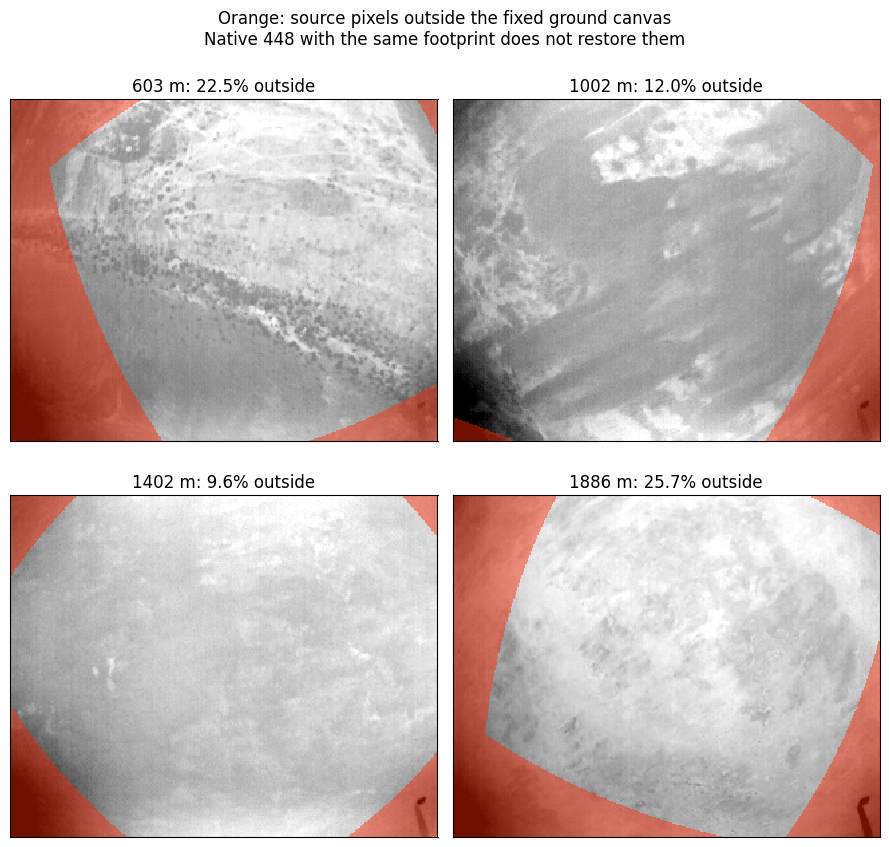

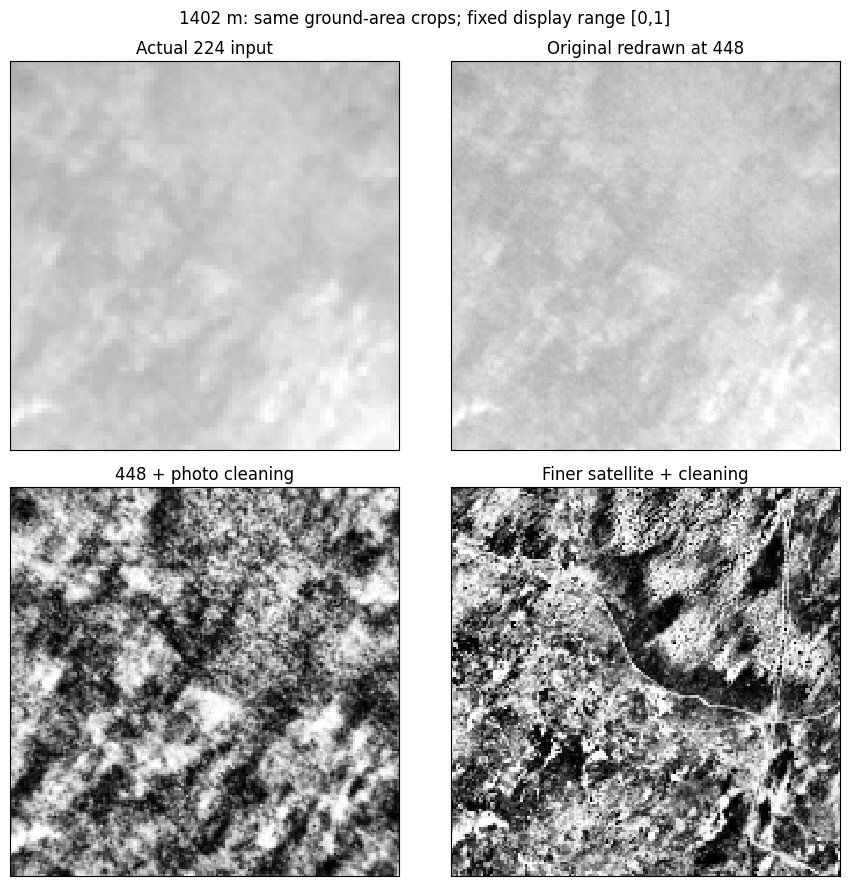

In [6]:
figure, axes = plt.subplots(2, 2, figsize=(9, 9))
for index, axis in enumerate(axes.flat):
    arrays = cases[index]
    axis.imshow(arrays['raw_display_only'], cmap='gray', vmin=0, vmax=1, interpolation='nearest')
    overlay = np.zeros((*arrays['source_inside_canvas'].shape, 4))
    overlay[~arrays['source_inside_canvas']] = [1, 0.15, 0, 0.45]
    axis.imshow(overlay, interpolation='nearest')
    axis.set_title(f"{measurements[index]['height_m']:.0f} m: {measurements[index]['source_centres_outside_canvas_percent']:.1f}% outside")
    axis.set_xticks([])
    axis.set_yticks([])
figure.suptitle('Orange: source pixels outside the fixed ground canvas\nNative 448 with the same footprint does not restore them')
figure.tight_layout()
figure.savefig(results / 'source_coverage_codex.png', dpi=150)
display(figure)
plt.close(figure)

figure, axes = plt.subplots(2, 2, figsize=(9, 9))
variants = [('base_photo', 'Actual 224 input'), ('native_photo', 'Original redrawn at 448'), ('clean_native_photo', '448 + photo cleaning'), ('clean_native_map', 'Finer satellite + cleaning')]
for axis, (name, title) in zip(axes.flat, variants):
    image = cases[2][name]
    lower = int(image.shape[0] * 0.3125)
    upper = int(image.shape[0] * 0.6875)
    axis.imshow(image[lower:upper, lower:upper], cmap='gray', vmin=0, vmax=1, interpolation='nearest')
    axis.set_title(title)
    axis.set_xticks([])
    axis.set_yticks([])
figure.suptitle('1402 m: same ground-area crops; fixed display range [0,1]')
figure.tight_layout()
figure.savefig(results / 'comparison_1402m_codex.png', dpi=160)
display(figure)
plt.close(figure)


## Interpretation

Read `REPORT_codex.md` for visual observations after inspecting the saved figures. The result to carry forward is a preservation candidate, not a validated score gain: direct higher-resolution rendering plus compatible cleaning on both modalities. Existing 142-frame true-place diagnostics favor that combination, while native-only and extra denoise/boost are worse. Full old-official/NUDT/new-development runs and deployment timing are still required. Defaults and trained weights remain unchanged.